# 05a — One-road starting advantage (5,000 games)
Run 01, 02 and 03 first. This is the unchanged one-road benchmark for comparison with the variable-road model in notebook 08. All files are local to `processed_data_5000/`. Select your installed Python environment in VS Code.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from advantage_model import build_advantage, affordable, readiness_curve, MAX_TURNS
from experiment_io import OUT, EXPECTED_GAMES, read_required, validate_players, same_players, validate_advantage

print("Working directory:", Path.cwd())
print("Input directory:", OUT.resolve())
p = validate_players(read_required(OUT,"initial_placements.csv","01_data_extraction.ipynb"),"initial placements")
t = read_required(OUT,"map_tiles.csv","01_data_extraction.ipynb")
f = validate_players(read_required(OUT,"initial_features.csv","03_feature_engineering.ipynb"),"initial features")
assert same_players(p,f), "Placement and feature game/player keys differ. Rerun 03."
assert not t.duplicated(["Game_ID","Tile_ID"]).any()
assert set(t.Game_ID)==set(p.Game_ID) and t.groupby("Game_ID").size().eq(19).all()
print(f"Validated {p.Game_ID.nunique():,} games, {len(p):,} players, {len(t):,} map tiles.")

Working directory: d:\Projects\catanatron-513project
Input directory: D:\Projects\catanatron-513project\processed_data_5000
Validated 5,000 games, 20,000 players, 95,000 map tiles.


In [2]:
# Verify exact affordability and zero-production boundary cases.
assert affordable((6,2,1,0,0))
assert not affordable((4,2,1,0,2))
assert affordable((0,0,0,0,24))
assert not affordable((0,0,0,0,23))
assert not affordable((6,2,1,0,0),trade=False)
zero=np.zeros((13,5),dtype=int)
assert np.allclose(readiness_curve((0,0,0,0,0),zero,8),0)
assert np.allclose(readiness_curve((2,2,1,1,0),zero,8),1)
print("Probability sanity checks passed.")

Probability sanity checks passed.


In [3]:
# Exact computation can take time. Progress is printed every 250 players.
# Set REUSE_EXISTING=True only if the existing outputs were generated for these same games.
REUSE_EXISTING = False
if REUSE_EXISTING:
    d = validate_advantage(read_required(OUT,"starting_advantage.csv","05a calculation"))
    curves = read_required(OUT,"readiness_curves.csv","05a calculation")
    assert same_players(d,p), "Existing scores do not match the current games."
else:
    d, curves = build_advantage(p,t,f)
    validate_advantage(d)
assert len(curves)==len(p)*MAX_TURNS
assert same_players(d,p)
assert same_players(curves[["Game_ID","Player"]].drop_duplicates(),p)
assert not curves.duplicated(["Game_ID","Player","Personal_Turn"]).any()
assert d.Player_Number.eq(d.Placement_Order).all()
assert d.Round_2_Order.eq(9-d.Player_Number).all()
if not REUSE_EXISTING:
    d.to_csv(OUT/"starting_advantage.csv",index=False)
    curves.to_csv(OUT/"readiness_curves.csv",index=False)
print("Saved or loaded",len(d),"positions and",len(curves),"readiness rows.")
display(d[["Game_ID","Player","Player_Number","Expansion_Options","Turns_To_50","Status"]].head())
display(d.Status.value_counts())
display(d.Turns_To_50.describe())

Readiness: 250/20,000 players
Readiness: 500/20,000 players
Readiness: 750/20,000 players
Readiness: 1,000/20,000 players
Readiness: 1,250/20,000 players
Readiness: 1,500/20,000 players
Readiness: 1,750/20,000 players
Readiness: 2,000/20,000 players
Readiness: 2,250/20,000 players
Readiness: 2,500/20,000 players
Readiness: 2,750/20,000 players
Readiness: 3,000/20,000 players
Readiness: 3,250/20,000 players
Readiness: 3,500/20,000 players
Readiness: 3,750/20,000 players
Readiness: 4,000/20,000 players
Readiness: 4,250/20,000 players
Readiness: 4,500/20,000 players
Readiness: 4,750/20,000 players
Readiness: 5,000/20,000 players
Readiness: 5,250/20,000 players
Readiness: 5,500/20,000 players
Readiness: 5,750/20,000 players
Readiness: 6,000/20,000 players
Readiness: 6,250/20,000 players
Readiness: 6,500/20,000 players
Readiness: 6,750/20,000 players
Readiness: 7,000/20,000 players
Readiness: 7,250/20,000 players
Readiness: 7,500/20,000 players
Readiness: 7,750/20,000 players
Readiness: 8,0

,Game_ID,Player,Player_Number,Expansion_Options,Turns_To_50,Status
0,000a8611-8efa-43ef-aa17-2b695845f514,ORANGE,1,2,21.0,Reached
1,000a8611-8efa-43ef-aa17-2b695845f514,RED,2,2,12.0,Reached
2,000a8611-8efa-43ef-aa17-2b695845f514,BLUE,3,1,6.0,Reached
3,000a8611-8efa-43ef-aa17-2b695845f514,WHITE,4,1,13.0,Reached
4,00248db7-8590-49d2-a14c-aa3e61ff5128,RED,1,3,18.0,Reached


Status
Reached           18741
Blocked             840
Beyond horizon      419
Name: count, dtype: int64

count    18741.000000
mean        12.050264
std          6.472389
min          3.000000
25%          8.000000
50%         10.000000
75%         15.000000
max         40.000000
Name: Turns_To_50, dtype: float64

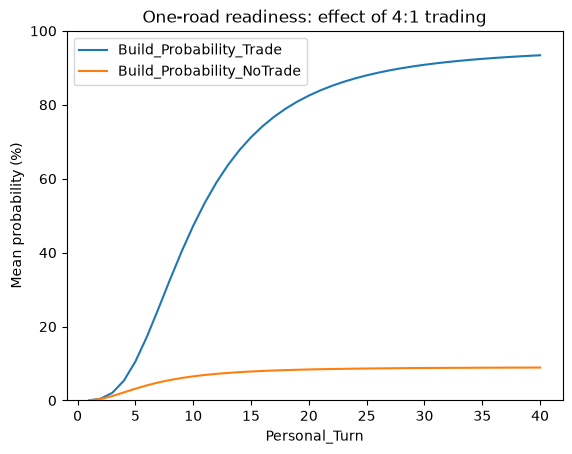

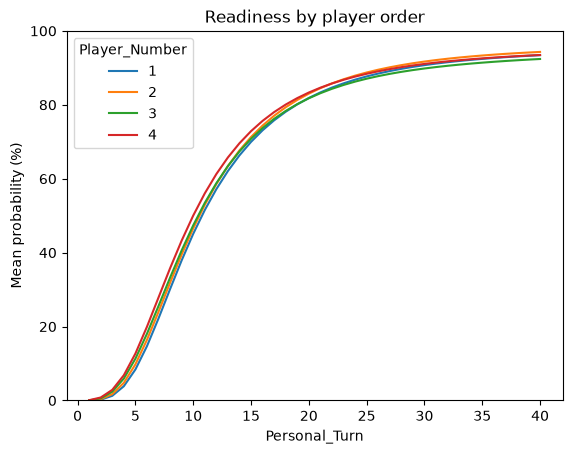

Turns_To_50        Prob_Turn_5           Prob_Turn_10            \
                     mean median        mean    median         mean    median   
Player_Number                                                                   
1               12.415316   11.0    0.083934  0.002264     0.450918  0.419222   
2               12.189046   10.0    0.097870  0.003423     0.465658  0.447386   
3               11.930283   10.0    0.113057  0.005152     0.473872  0.469835   
4               11.664038   10.0    0.126983  0.011022     0.500353  0.540211   

              Blocked         
                 mean median  
Player_Number                 
1              0.0418    0.0  
2              0.0344    0.0  
3              0.0490    0.0  
4              0.0428    0.0

In [4]:
avg=curves.groupby("Personal_Turn")[["Build_Probability_Trade","Build_Probability_NoTrade"]].mean()
(avg*100).plot(); plt.ylabel("Mean probability (%)"); plt.ylim(0,100); plt.title("One-road readiness: effect of 4:1 trading"); plt.show()
by_order=curves.pivot_table(index="Personal_Turn",columns="Player_Number",values="Build_Probability_Trade")
(by_order*100).plot(); plt.ylabel("Mean probability (%)"); plt.ylim(0,100); plt.title("Readiness by player order"); plt.show()
display(d.groupby("Player_Number")[["Turns_To_50","Prob_Turn_5","Prob_Turn_10","Blocked"]].agg(["mean","median"]))

The theoretical model holds the initial board and production fixed; no robber, discards, ports or opponent actions are modeled. Blocked means no one-road site, not permanent inability to expand. Notebook 08 tests additional roads.